Butterworth Filter Coefficients:
Numerator (b):
[1.29607191e-05 5.18428766e-05 7.77643148e-05 5.18428766e-05
 1.29607191e-05]
Denominator (a):
[ 1.         -3.67388572  5.07378356 -3.12116011  0.72146964]


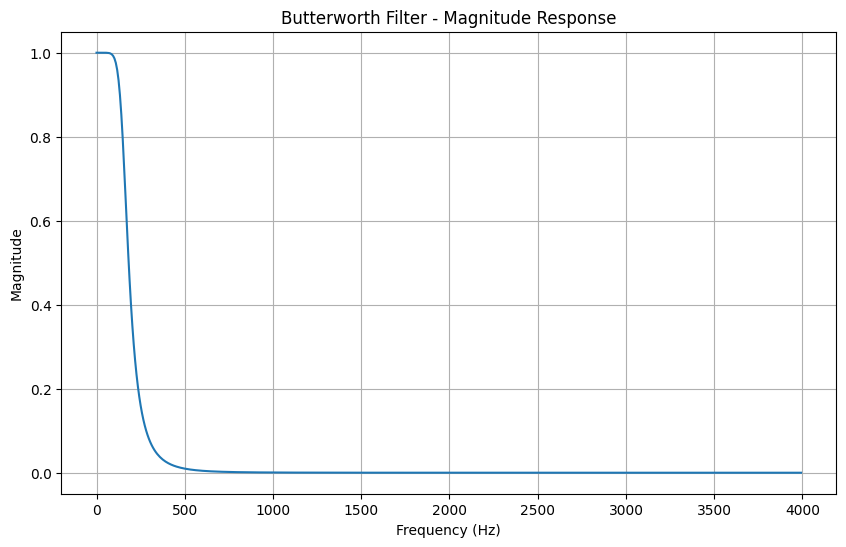

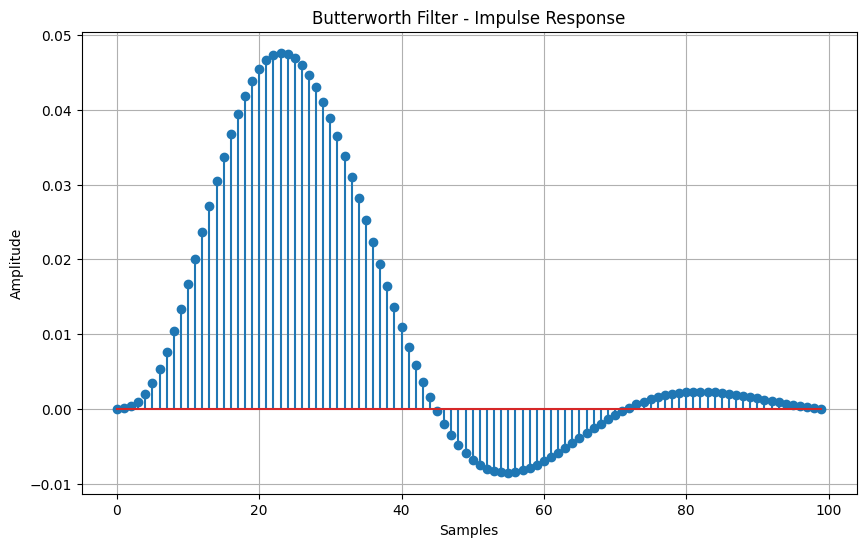


Chebyshev Filter Coefficients:
Numerator (b):
[5.04743397e-06 2.01897359e-05 3.02846038e-05 2.01897359e-05
 5.04743397e-06]
Denominator (a):
[ 1.         -3.83541526  5.53394882 -3.55962935  0.86118134]


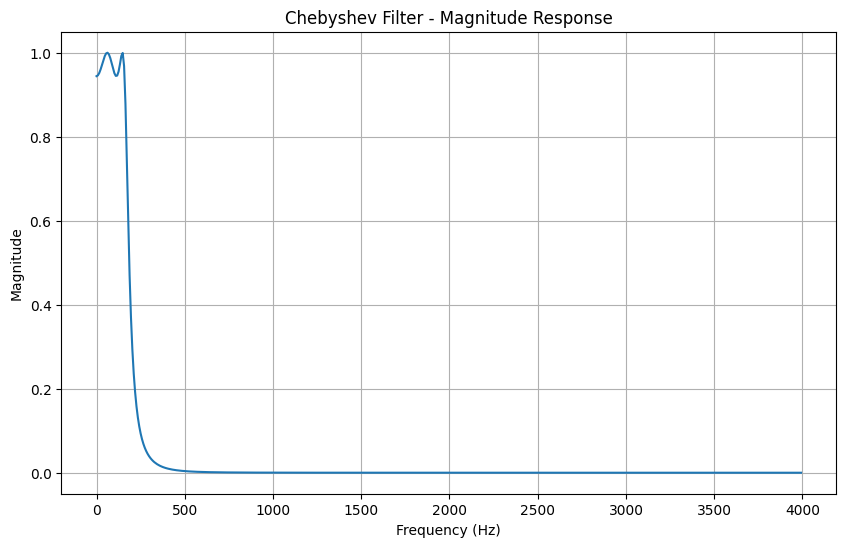

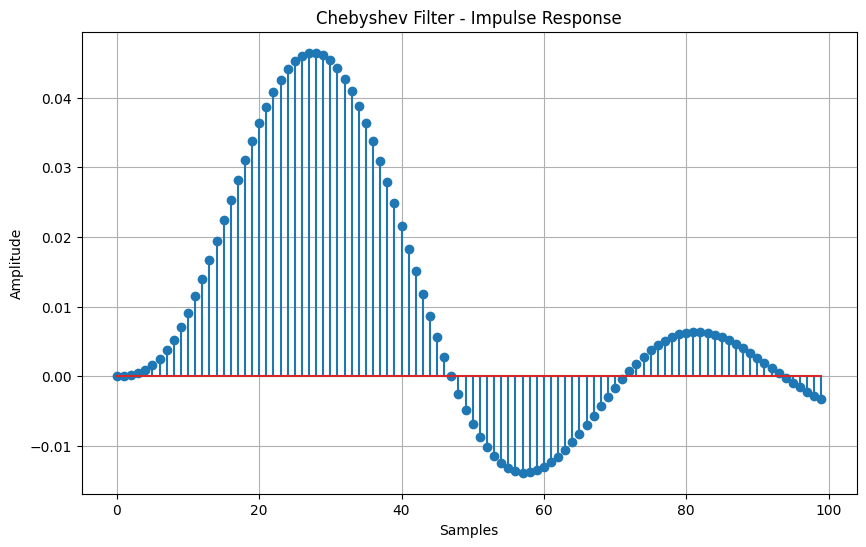


Filter coefficients saved at: filter_coefficients.txt


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1, lfilter


# Design Butterworth Filter
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):

    analog_b, analog_a = butter(
        filter_order,
        cutoff_frequency,
        analog=True,
        btype='low'
    )

    digital_b, digital_a = bilinear(
        analog_b,
        analog_a,
        sampling_frequency
    )

    return digital_b, digital_a


# Design Chebyshev Filter
def design_chebyshev_filter(
    filter_order,
    cutoff_frequency,
    sampling_frequency,
    ripple
):

    analog_b, analog_a = cheby1(
        filter_order,
        ripple,
        cutoff_frequency,
        analog=True,
        btype='low'
    )

    digital_b, digital_a = bilinear(
        analog_b,
        analog_a,
        sampling_frequency
    )

    return digital_b, digital_a


# Plot Filter Response
def plot_filter_response(
    digital_b,
    digital_a,
    sampling_frequency,
    filter_name
):

    # Frequency response
    frequency, response = freqz(
        digital_b,
        digital_a,
        fs=sampling_frequency
    )

    # Magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(response))

    plt.title(filter_name + " - Magnitude Response")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.grid(True)
    plt.show()

    # Impulse signal
    impulse = np.zeros(100)
    impulse[0] = 1

    # Impulse response
    impulse_response = lfilter(
        digital_b,
        digital_a,
        impulse
    )

    # Plot impulse response
    plt.figure(figsize=(10, 6))
    plt.stem(
        range(len(impulse_response)),
        impulse_response
    )

    plt.title(filter_name + " - Impulse Response")
    plt.xlabel("Samples")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()


# --------------------------------------------------
# Filter Specifications
# --------------------------------------------------

filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5


# --------------------------------------------------
# Butterworth Filter
# --------------------------------------------------

digital_b, digital_a = design_butterworth_filter(
    filter_order,
    cutoff_frequency,
    sampling_frequency
)

print("Butterworth Filter Coefficients:")
print("Numerator (b):")
print(digital_b)

print("Denominator (a):")
print(digital_a)

plot_filter_response(
    digital_b,
    digital_a,
    sampling_frequency,
    "Butterworth Filter"
)


# --------------------------------------------------
# Chebyshev Filter
# --------------------------------------------------

digital_b, digital_a = design_chebyshev_filter(
    filter_order,
    cutoff_frequency,
    sampling_frequency,
    ripple
)

print("\nChebyshev Filter Coefficients:")
print("Numerator (b):")
print(digital_b)

print("Denominator (a):")
print(digital_a)

plot_filter_response(
    digital_b,
    digital_a,
    sampling_frequency,
    "Chebyshev Filter"
)


# --------------------------------------------------
# Save Filter Coefficients
# --------------------------------------------------

filter_path = "filter_coefficients.txt"

np.savetxt(
    filter_path,
    np.vstack((digital_b, digital_a)),
    delimiter=","
)

print("\nFilter coefficients saved at:", filter_path)

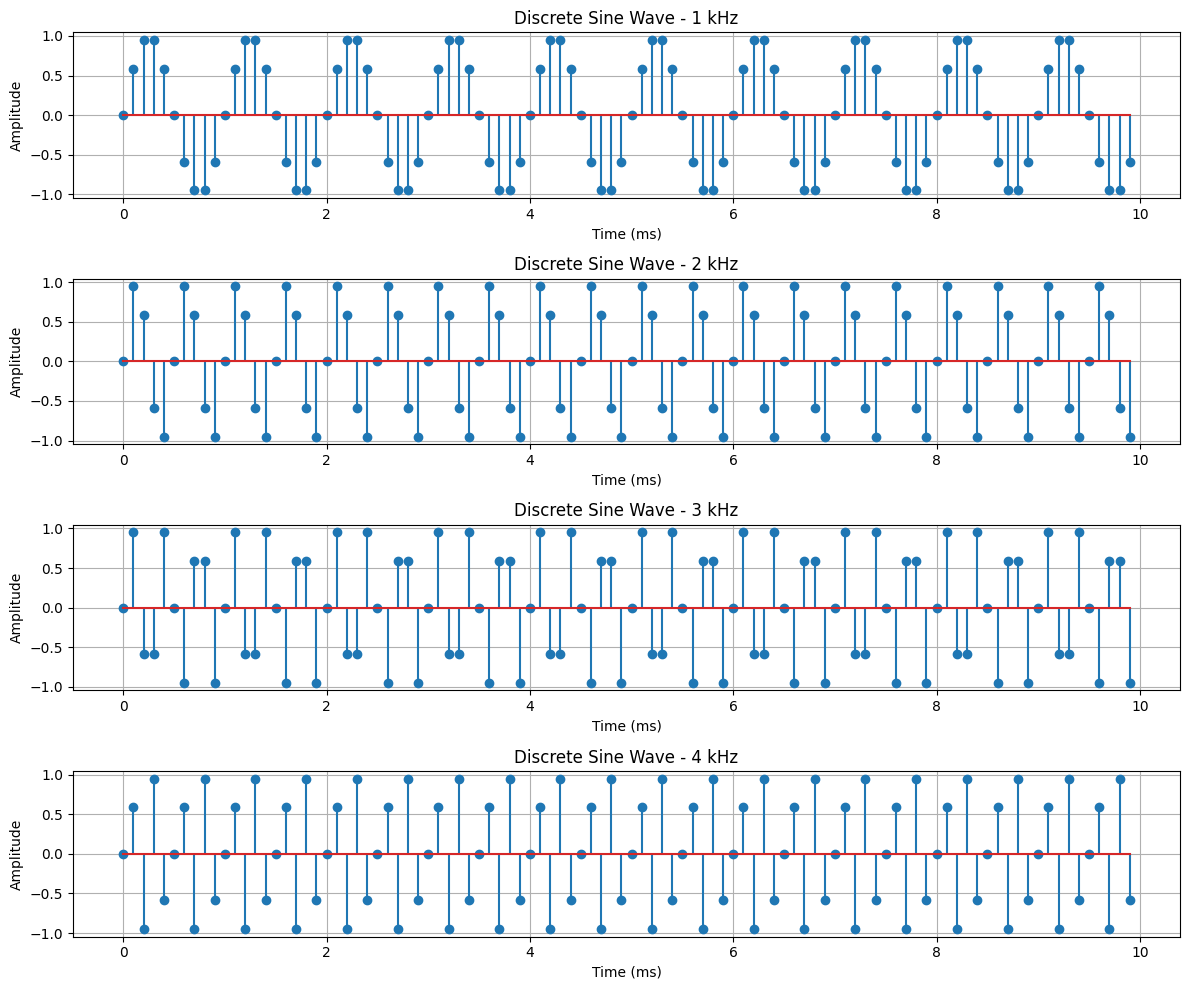

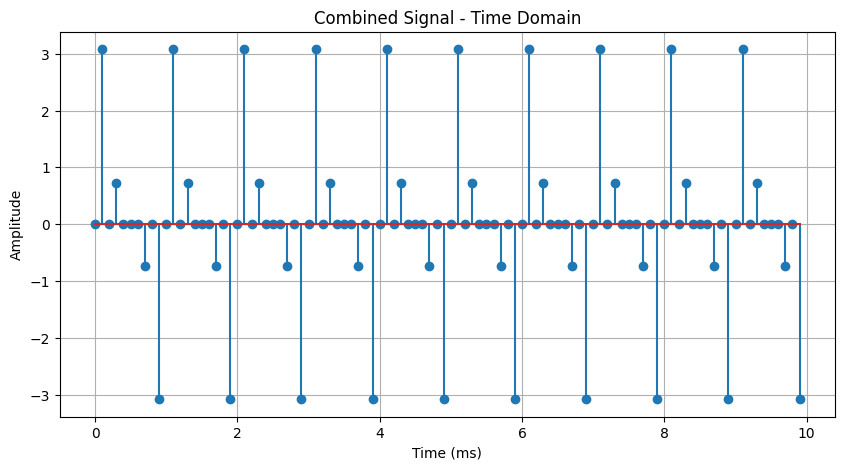

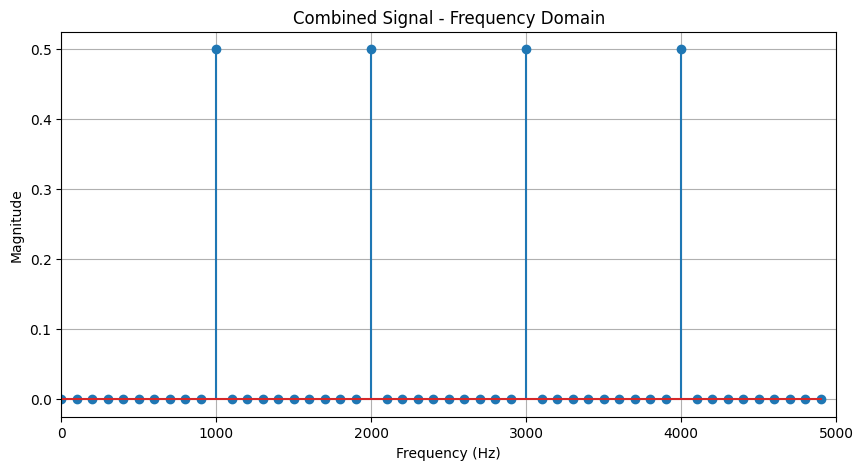

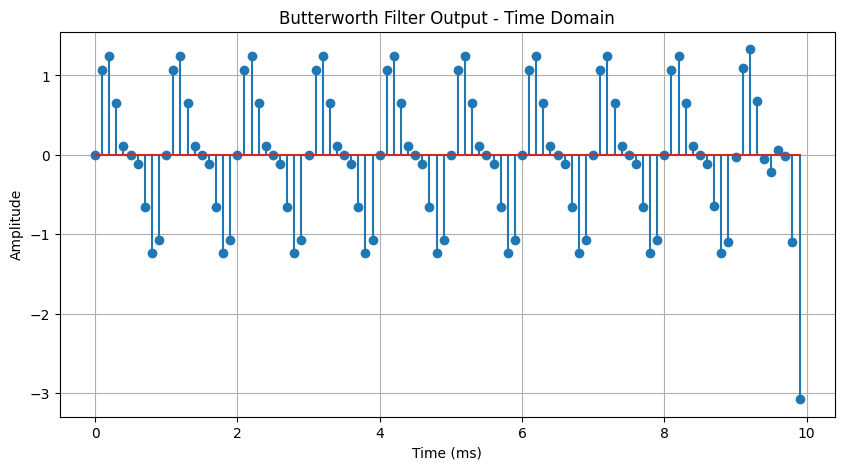

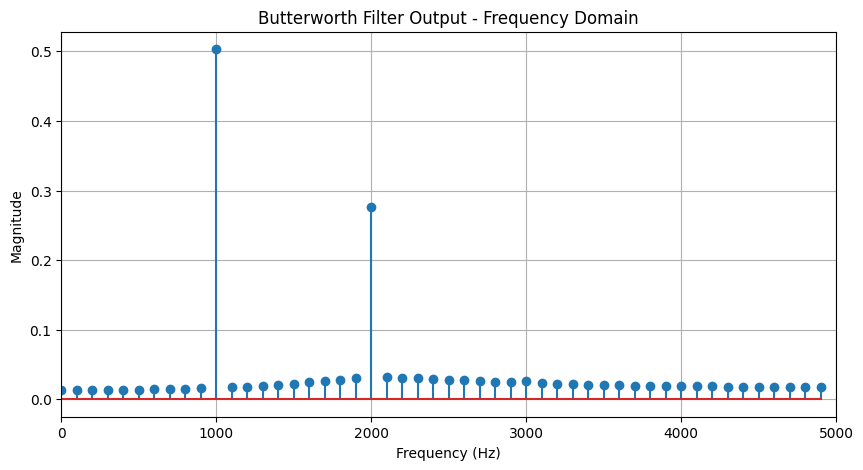

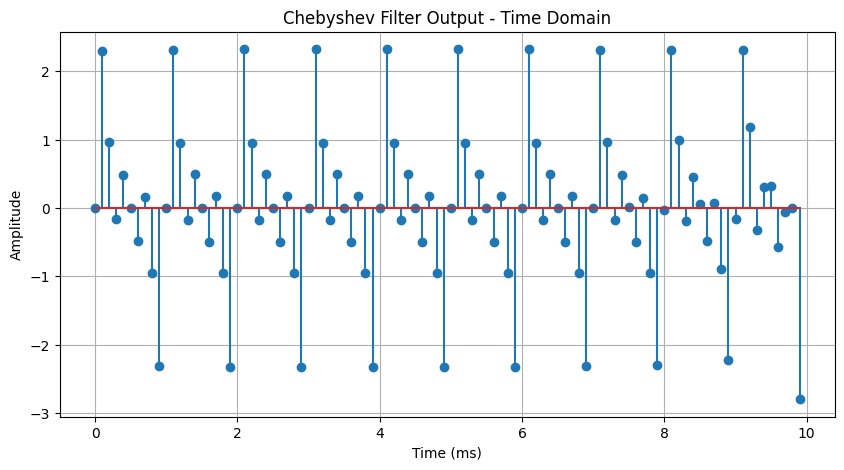

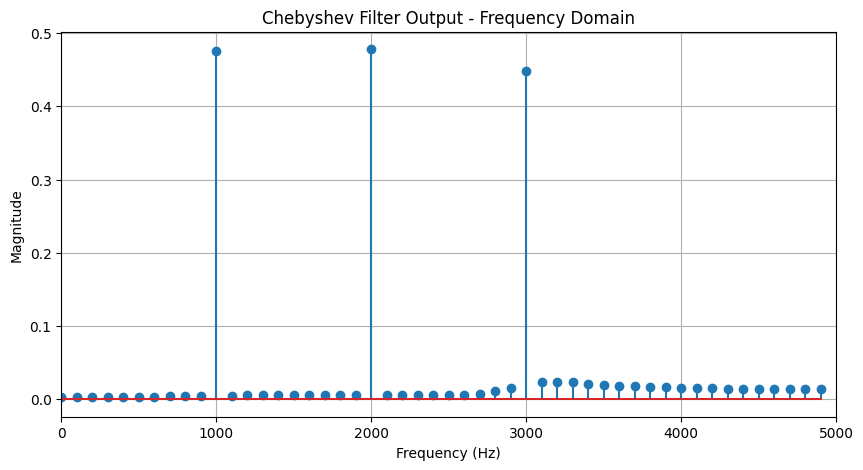

DSIP DIGITAL FILTERING

Sampling Frequency: 10000 Hz

Input Frequencies:
1. 1 kHz
2. 2 kHz
3. 3 kHz
4. 4 kHz

Butterworth Filter:
Order: 4
Cutoff Frequency: 2000 Hz

Chebyshev Type-I Filter:
Order: 4
Cutoff Frequency: 3000 Hz
Ripple: 0.5 dB

Program completed successfully.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, filtfilt


# ==========================================================
# 1. SIGNAL PARAMETERS
# ==========================================================

fs = 10000              # Sampling frequency = 10 kHz
duration = 0.01         # Signal duration = 10 ms

t = np.arange(0, duration, 1 / fs)

# Frequencies of the four signals
f1 = 1000               # 1 kHz
f2 = 2000               # 2 kHz
f3 = 3000               # 3 kHz
f4 = 4000               # 4 kHz


# ==========================================================
# 2. GENERATE DISCRETE SINE WAVES
# ==========================================================

x1 = np.sin(2 * np.pi * f1 * t)
x2 = np.sin(2 * np.pi * f2 * t)
x3 = np.sin(2 * np.pi * f3 * t)
x4 = np.sin(2 * np.pi * f4 * t)


# ==========================================================
# 3. PLOT ALL FOUR DISCRETE SIGNALS
# ==========================================================

plt.figure(figsize=(12, 10))

plt.subplot(4, 1, 1)
plt.stem(t * 1000, x1)
plt.title("Discrete Sine Wave - 1 kHz")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.stem(t * 1000, x2)
plt.title("Discrete Sine Wave - 2 kHz")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.stem(t * 1000, x3)
plt.title("Discrete Sine Wave - 3 kHz")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 4)
plt.stem(t * 1000, x4)
plt.title("Discrete Sine Wave - 4 kHz")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. ADD ALL FOUR SIGNALS
# ==========================================================

x_sum = x1 + x2 + x3 + x4


# ==========================================================
# 5. TIME DOMAIN OF COMBINED SIGNAL
# ==========================================================

plt.figure(figsize=(10, 5))

plt.stem(t * 1000, x_sum)

plt.title("Combined Signal - Time Domain")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()


# ==========================================================
# 6. FREQUENCY DOMAIN OF COMBINED SIGNAL
# ==========================================================

N = len(x_sum)

X = np.fft.fft(x_sum)

frequencies = np.fft.fftfreq(N, 1 / fs)

# Take only positive frequencies
positive = frequencies >= 0

plt.figure(figsize=(10, 5))

plt.stem(
    frequencies[positive],
    np.abs(X[positive]) / N
)

plt.title("Combined Signal - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.grid(True)

plt.show()


# ==========================================================
# 7. BUTTERWORTH DIGITAL LOW-PASS FILTER
# ==========================================================

butterworth_order = 4
butterworth_cutoff = 2000       # 2 kHz

# Normalize cutoff frequency
Wn_butterworth = butterworth_cutoff / (fs / 2)

b_butter, a_butter = butter(
    butterworth_order,
    Wn_butterworth,
    btype="low"
)

# Apply Butterworth filter
butter_output = filtfilt(
    b_butter,
    a_butter,
    x_sum
)


# ==========================================================
# 8. BUTTERWORTH OUTPUT - TIME DOMAIN
# ==========================================================

plt.figure(figsize=(10, 5))

plt.stem(t * 1000, butter_output)

plt.title("Butterworth Filter Output - Time Domain")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()


# ==========================================================
# 9. BUTTERWORTH OUTPUT - FREQUENCY DOMAIN
# ==========================================================

B = np.fft.fft(butter_output)

plt.figure(figsize=(10, 5))

plt.stem(
    frequencies[positive],
    np.abs(B[positive]) / N
)

plt.title("Butterworth Filter Output - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.grid(True)

plt.show()


# ==========================================================
# 10. CHEBYSHEV TYPE-I DIGITAL LOW-PASS FILTER
# ==========================================================

chebyshev_order = 4
chebyshev_cutoff = 3000       # 3 kHz
ripple = 0.5                  # 0.5 dB ripple

# Normalize cutoff frequency
Wn_chebyshev = chebyshev_cutoff / (fs / 2)

b_cheby, a_cheby = cheby1(
    chebyshev_order,
    ripple,
    Wn_chebyshev,
    btype="low"
)

# Apply Chebyshev filter
cheby_output = filtfilt(
    b_cheby,
    a_cheby,
    x_sum
)


# ==========================================================
# 11. CHEBYSHEV OUTPUT - TIME DOMAIN
# ==========================================================

plt.figure(figsize=(10, 5))

plt.stem(t * 1000, cheby_output)

plt.title("Chebyshev Filter Output - Time Domain")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()


# ==========================================================
# 12. CHEBYSHEV OUTPUT - FREQUENCY DOMAIN
# ==========================================================

C = np.fft.fft(cheby_output)

plt.figure(figsize=(10, 5))

plt.stem(
    frequencies[positive],
    np.abs(C[positive]) / N
)

plt.title("Chebyshev Filter Output - Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 5000)
plt.grid(True)

plt.show()


# ==========================================================
# 13. PRINT FILTER INFORMATION
# ==========================================================

print("==========================================")
print("DSIP DIGITAL FILTERING")
print("==========================================")

print("\nSampling Frequency:", fs, "Hz")

print("\nInput Frequencies:")
print("1. 1 kHz")
print("2. 2 kHz")
print("3. 3 kHz")
print("4. 4 kHz")

print("\nButterworth Filter:")
print("Order:", butterworth_order)
print("Cutoff Frequency:", butterworth_cutoff, "Hz")

print("\nChebyshev Type-I Filter:")
print("Order:", chebyshev_order)
print("Cutoff Frequency:", chebyshev_cutoff, "Hz")
print("Ripple:", ripple, "dB")

print("\nProgram completed successfully.")